In [39]:
from medmnist import PathMNIST
from torchvision import transforms

In [40]:
transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train = PathMNIST(split="train", transform=transform, download=False)
val   = PathMNIST(split="val",   transform=transform, download=False)
test  = PathMNIST(split="test",  transform=transform, download=False)

In [41]:
# Dataset info
print(f"Training samples: {len(train)}")
print(f"Validation samples: {len(val)}")
print(f"Test samples: {len(test)}")
print(f"Image shape: {train[0][0].shape}")
print(f"Number of classes: {len(train.info['label'])}")
print(f"Class labels: {train.info['label']}")

Training samples: 89996
Validation samples: 10004
Test samples: 7180
Image shape: torch.Size([3, 100, 100])
Number of classes: 9
Class labels: {'0': 'adipose', '1': 'background', '2': 'debris', '3': 'lymphocytes', '4': 'mucus', '5': 'smooth muscle', '6': 'normal colon mucosa', '7': 'cancer-associated stroma', '8': 'colorectal adenocarcinoma epithelium'}


In [42]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import models
from tqdm import tqdm

# Configuration
BATCH_SIZE = 128
NUM_EPOCHS = 20
LEARNING_RATE = 0.001

# Use MPS (Metal Performance Shaders) for faster training on macOS
if torch.backends.mps.is_available():
    device = torch.device('mps')
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print(train)

else:
    print("train is:")

    device = torch.device('cpu')

    print(f'Using device: {device}')

In [43]:
# Create combined training dataset
from torch.utils.data import ConcatDataset
full_train = ConcatDataset([train, val])

# Create data loaders
train_loader = DataLoader(full_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f'Training batches: {len(train_loader)}')

# Create subset data loaders for faster training (25% of data)
from torch.utils.data import Subset
import numpy as np

x_train_indices = np.arange(0, int(len(train)/4))
x_val_indices = np.arange(0, int(len(val)/4))

x_train = Subset(train, x_train_indices)
x_val = Subset(val, x_val_indices)


x_train_loader = DataLoader(x_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
print(f'Reduced training batches: {len(x_train_loader)} (25% of data)')

x_val_loader = DataLoader(x_val, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

Training batches: 782
Reduced training batches: 176 (25% of data)


In [44]:
images, labels = next(iter(train_loader))
image = images[0]
print(image.shape)

torch.Size([3, 100, 100])


In [45]:
import torch.nn as nn
import torchvision.models as models

class ResNet18Medical(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.model = models.resnet18(pretrained=True)

        self.model.fc = nn.Linear(
            self.model.fc.in_features,
            num_classes
        )

    def forward(self, x):
        return self.model(x)

In [46]:
# Initialize ResNet18Medical model
medical_model = ResNet18Medical(num_classes=len(train.info['label']))
medical_model = medical_model.to(device)
print(f'ResNet18Medical loaded with {len(train.info["label"])} output classes')

ResNet18Medical loaded with 9 output classes


In [47]:
# Loss function and optimizer for medical model
medical_criterion = nn.CrossEntropyLoss()
medical_optimizer = optim.SGD(
    medical_model.parameters(),
    lr=0.001,
    momentum=0.9,
    weight_decay=1e-4
)

In [48]:
# Training loop for ResNet18Medical
medical_history = {'train_loss': [], 'train_acc': []}
best_medical_val_acc = 0.0

for epoch in range(NUM_EPOCHS):
    print(f'\nEpoch {epoch+1}/{NUM_EPOCHS}')
    print('-' * 50)
    
    # Training phase
    medical_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    
    for images, labels in tqdm(train_loader, desc='Training'):
        images = images.to(device)
        labels = labels.squeeze().long().to(device)
        
        medical_optimizer.zero_grad()
        outputs = medical_model(images)
        loss = medical_criterion(outputs, labels)
        loss.backward()
        medical_optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = 100 * train_correct / train_total
    
    # Save history
    medical_history['train_loss'].append(epoch_train_loss)
    medical_history['train_acc'].append(epoch_train_acc)
    
    print(f'Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%')

print(f'\nTraining complete!')


Epoch 1/20
--------------------------------------------------


Training: 100%|██████████| 782/782 [03:17<00:00,  3.96it/s]


Train Loss: 0.3141 | Train Acc: 89.64%

Epoch 2/20
--------------------------------------------------


Training: 100%|██████████| 782/782 [03:54<00:00,  3.33it/s]


Train Loss: 0.1198 | Train Acc: 96.03%

Epoch 3/20
--------------------------------------------------


...

Train Loss: 0.0029 | Train Acc: 99.95%

Epoch 19/20
--------------------------------------------------


Training: 100%|██████████| 782/782 [04:18<00:00,  3.03it/s]


Train Loss: 0.0026 | Train Acc: 99.96%

Epoch 20/20
--------------------------------------------------


Training: 100%|██████████| 782/782 [04:44<00:00,  2.75it/s]

Train Loss: 0.0021 | Train Acc: 99.97%

Training complete!


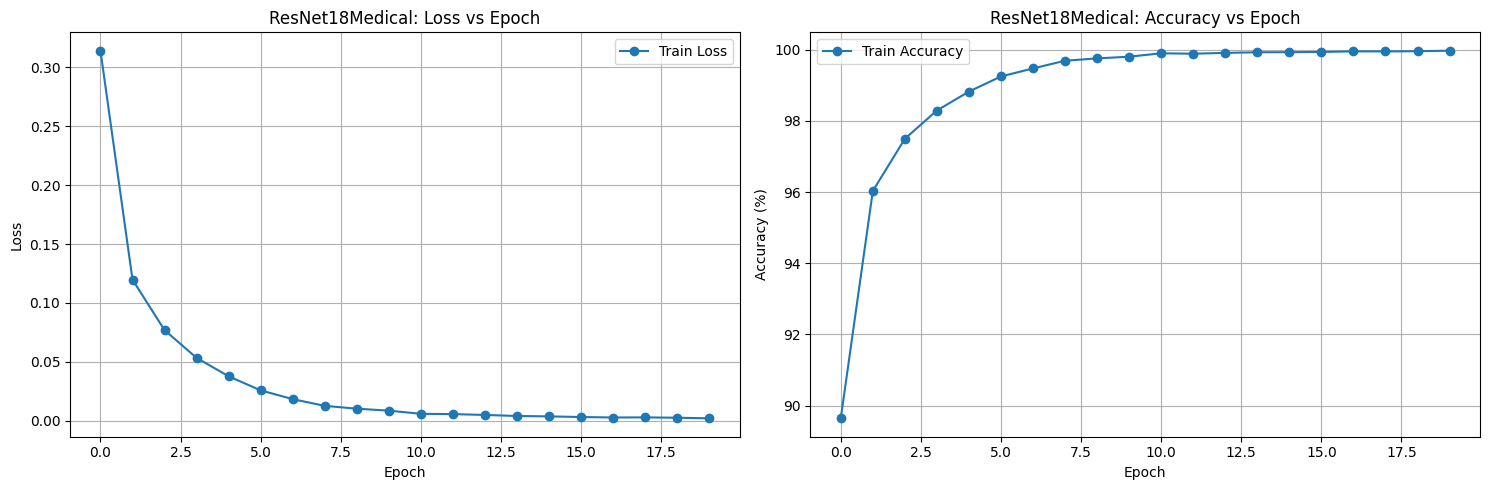

In [51]:
import matplotlib.pyplot as plt
# Plot training history for ResNet18Medical
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Loss plot
ax1.plot(medical_history['train_loss'], label='Train Loss', marker='o')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('ResNet18Medical: Loss vs Epoch')
ax1.legend()
ax1.grid(True)

# Accuracy plot
ax2.plot(medical_history['train_acc'], label='Train Accuracy', marker='o')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('ResNet18Medical: Accuracy vs Epoch')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [52]:
# Evaluate ResNet18Medical on test set
medical_model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='Testing ResNet18Medical'):
        images = images.to(device)
        labels = labels.squeeze().long().to(device)
        
        outputs = medical_model(images)
        _, predicted = torch.max(outputs, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

test_acc = 100 * test_correct / test_total
print(f'ResNet18Medical Test Accuracy: {test_acc:.2f}%')

Testing ResNet18Medical: 100%|██████████| 57/57 [00:17<00:00,  3.34it/s]

ResNet18Medical Test Accuracy: 91.74%


In [53]:
# Save model with test accuracy in filename

model_filename = f"../models/resnet18_full_{test_acc:.2f}_pathmnist.pth"
print(f"Model saved as {model_filename}")
torch.save(medical_model.state_dict(), model_filename)

Model saved as ../models/resnet18_full_91.74_pathmnist.pth


# Breast Cancer Dataset Training

In [54]:
# Load Breast Cancer Dataset
from torchvision.datasets import ImageFolder
from sklearn.model_selection import train_test_split
import os

# Define transforms for breast cancer dataset
bc_transform = transforms.Compose([
    transforms.Resize((100, 100)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load full dataset
data_dir = '../data'
full_dataset = ImageFolder(root=data_dir, transform=bc_transform)

print(f"Total breast cancer images: {len(full_dataset)}")
print(f"Classes: {full_dataset.classes}")
print(f"Class to index mapping: {full_dataset.class_to_idx}")

Total breast cancer images: 7909
Classes: ['benign', 'malignant']
Class to index mapping: {'benign': 0, 'malignant': 1}


In [55]:
# Split dataset into train, validation, and test sets
from torch.utils.data import Subset

# Get indices for each class
indices = list(range(len(full_dataset)))
targets = [full_dataset.targets[i] for i in indices]

print(f"Total available images: {len(full_dataset)}")

# Calculate split sizes based on available data
# Target: 7000 train, 1109 val, 1000 test if enough data
total_samples = len(full_dataset)
if total_samples >= 9109:
    train_size = 7000
    val_size = 1109
    test_size = 1000
else:
    # Proportional split maintaining the ratios
    train_size = int(total_samples * 0.7684)  # 7000/9109
    val_size = int(total_samples * 0.1218)    # 1109/9109
    test_size = total_samples - train_size - val_size

print(f"Using split - Train: {train_size}, Val: {val_size}, Test: {test_size}")

# Split: First get training set
train_indices, temp_indices = train_test_split(
    indices, train_size=train_size, stratify=targets, random_state=42
)

# Then split remaining into val and test
temp_targets = [targets[i] for i in temp_indices]
remaining = len(temp_indices)
val_ratio = val_size / (val_size + test_size)
val_actual = int(remaining * val_ratio)

val_indices, test_indices = train_test_split(
    temp_indices, train_size=val_actual, stratify=temp_targets, random_state=42
)

# Create datasets
bc_train_dataset = Subset(full_dataset, train_indices)
bc_val_dataset = Subset(full_dataset, val_indices)
bc_test_dataset = Subset(full_dataset, test_indices)

# Don't use validation during training - only train and test
bc_full_train = bc_train_dataset

# Create data loaders
bc_train_loader = DataLoader(bc_full_train, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
bc_test_loader = DataLoader(bc_test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Training batches: {len(bc_train_loader)}")
print(f"Breast Cancer - Train: {len(bc_train_dataset)}, Val: {len(bc_val_dataset)}, Test: {len(bc_test_dataset)}")

Total available images: 7909
Using split - Train: 6077, Val: 963, Test: 869
Training batches: 48
Breast Cancer - Train: 6077, Val: 962, Test: 870


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.547619..2.186841].


Breast Cancer Image shape: torch.Size([3, 100, 100])
Label: Malignant


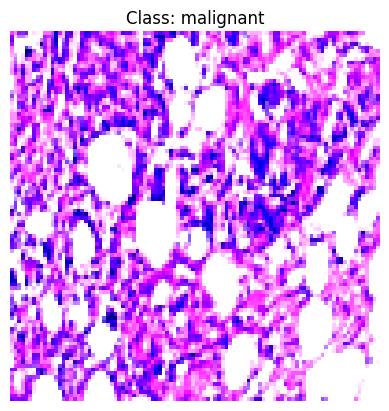

In [56]:
# Visualize a sample from breast cancer dataset
bc_images, bc_labels = next(iter(bc_train_loader))
bc_image = bc_images[0]

print(f'Breast Cancer Image shape: {bc_image.shape}')
print(f'Label: {"Malignant" if bc_labels[0].item() == 1 else "Benign"}')

import matplotlib.pyplot as plt
plt.imshow(bc_image.permute(1, 2, 0).cpu().numpy())
plt.title(f'Class: {full_dataset.classes[bc_labels[0].item()]}')
plt.axis('off')
plt.show()

In [57]:
# Initialize ResNet18 for Breast Cancer (Binary Classification)
class ResNet18BreastCancer(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.model = models.resnet18(pretrained=True)
        
        # Replace final layer for binary classification
        self.model.fc = nn.Linear(
            self.model.fc.in_features,
            num_classes
        )
    
    def forward(self, x):
        return self.model(x)

bc_model = ResNet18BreastCancer(num_classes=2)
bc_model = bc_model.to(device)
print(f'ResNet18 for Breast Cancer loaded with 2 output classes (Benign/Malignant)')

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


ResNet18 for Breast Cancer loaded with 2 output classes (Benign/Malignant)


In [58]:
# Loss function and optimizer for breast cancer model
bc_criterion = nn.CrossEntropyLoss()
bc_optimizer = optim.SGD(
    bc_model.parameters(),
    lr=0.001,
    momentum=0.9,
    weight_decay=1e-4
)

In [61]:
# Training loop for Breast Cancer ResNet18
bc_history = {'train_loss': [], 'train_acc': []}
best_bc_val_acc = 0.0

for epoch in range(NUM_EPOCHS):
    print(f'\nEpoch {epoch+1}/{NUM_EPOCHS}')
    print('-' * 50)
    
    # Training phase
    bc_model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0
    
    for images, labels in tqdm(bc_train_loader, desc='Training BC'):
        images = images.to(device)
        labels = labels.to(device)
        
        bc_optimizer.zero_grad()
        outputs = bc_model(images)
        loss = bc_criterion(outputs, labels)
        loss.backward()
        bc_optimizer.step()
        
        train_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        train_total += labels.size(0)
        train_correct += (predicted == labels).sum().item()
    
    epoch_train_loss = train_loss / train_total
    epoch_train_acc = 100 * train_correct / train_total
    
    # Save history
    bc_history['train_loss'].append(epoch_train_loss)
    bc_history['train_acc'].append(epoch_train_acc)
    
    print(f'Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}%')

print(f'\nTraining complete!')


Epoch 1/20
--------------------------------------------------


Training BC: 100%|██████████| 48/48 [00:31<00:00,  1.50it/s]


Train Loss: 0.5134 | Train Acc: 75.51%

Epoch 2/20
--------------------------------------------------


Training BC: 100%|██████████| 48/48 [00:31<00:00,  1.54it/s]


Train Loss: 0.2593 | Train Acc: 89.85%

Epoch 3/20
--------------------------------------------------


...

Train Loss: 0.0038 | Train Acc: 100.00%

Epoch 19/20
--------------------------------------------------


Training BC: 100%|██████████| 48/48 [00:38<00:00,  1.24it/s]


Train Loss: 0.0042 | Train Acc: 99.98%

Epoch 20/20
--------------------------------------------------


Training BC: 100%|██████████| 48/48 [00:38<00:00,  1.25it/s]

Train Loss: 0.0027 | Train Acc: 100.00%

Training complete!


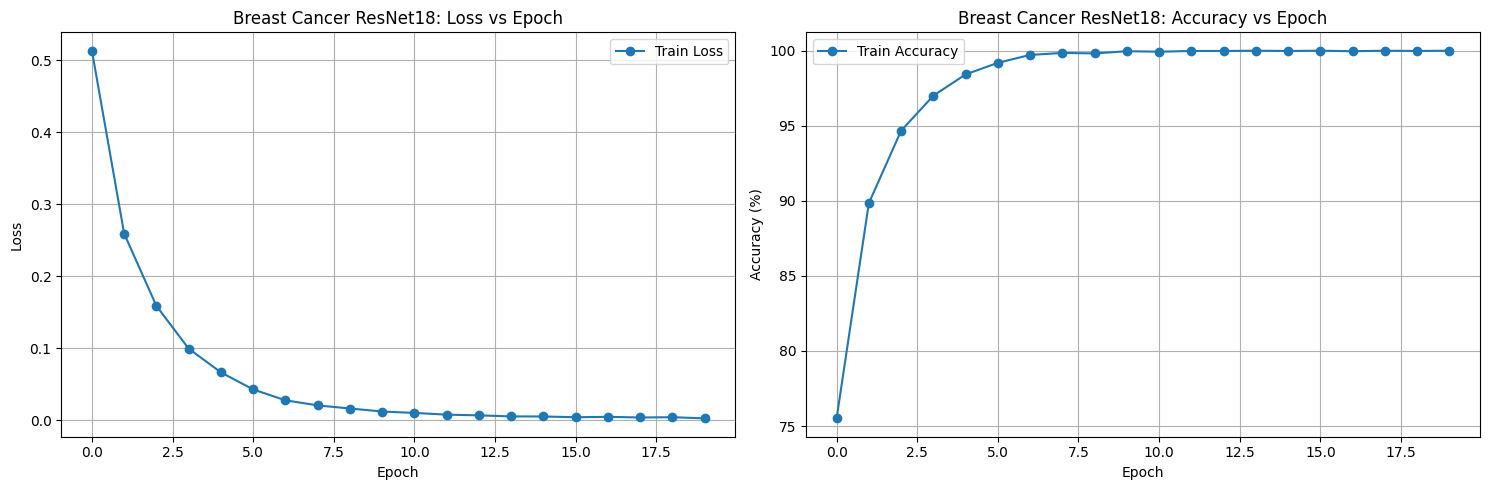

In [62]:
# Plot training history for Breast Cancer ResNet18
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Loss plot
ax1.plot(bc_history['train_loss'], label='Train Loss', marker='o')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.set_title('Breast Cancer ResNet18: Loss vs Epoch')
ax1.legend()
ax1.grid(True)

# Accuracy plot
ax2.plot(bc_history['train_acc'], label='Train Accuracy', marker='o')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.set_title('Breast Cancer ResNet18: Accuracy vs Epoch')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

In [63]:
# Evaluate Breast Cancer ResNet18 on test set
bc_model.eval()
test_correct = 0
test_total = 0

with torch.no_grad():
    for images, labels in tqdm(bc_test_loader, desc='Testing BC ResNet18'):
        images = images.to(device)
        labels = labels.to(device)
        
        outputs = bc_model(images)
        _, predicted = torch.max(outputs, 1)
        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

bc_test_acc = 100 * test_correct / test_total
print(f'Breast Cancer ResNet18 Test Accuracy: {bc_test_acc:.2f}%')

Testing BC ResNet18: 100%|██████████| 7/7 [00:14<00:00,  2.09s/it]

Breast Cancer ResNet18 Test Accuracy: 93.10%


In [64]:
# Save model with test accuracy in filename
model_filename = f"../models/resnet18_full_{bc_test_acc:.2f}_bc.pth"
torch.save(bc_model.state_dict(), model_filename)
print(f"Model saved as {model_filename}")

Model saved as ../models/resnet18_full_93.10_bc.pth
